# Solutions to notebook 10: Quadrature: integrating with spectral accuracy

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/solutions/10_quadrature.ipynb)

Worked solutions to the exercises at the end of [notebook 10](../notebooks/10_quadrature.ipynb).
Try each exercise yourself before reading its solution: the struggle is where the learning happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import dct
from scipy.linalg import eigh_tridiagonal
from scipy.special import ellipk

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

In [2]:
# functions from notebook 10
def periodic_trapezoid(f, N, period=2 * np.pi):
    """Trapezoidal rule over one period: the period times the mean of N equally spaced samples."""
    return period * np.mean(f(period * np.arange(N) / N))

def clenshaw_curtis(N):
    """Clenshaw-Curtis nodes (the Chebyshev points) and weights on [-1, 1]."""
    if N == 0:
        return np.ones(1), np.array([2.0])
    x = np.cos(np.pi * np.arange(N + 1) / N)
    moments = np.zeros(N + 1)
    even = np.arange(0, N + 1, 2)
    moments[even] = 2 / (1 - even.astype(float) ** 2)             # integrals of T_k; zero for odd k
    w = dct(moments, type=1) / N                                   # cosine transform of the moments
    w[0] /= 2
    w[N] /= 2
    return x, w

def gauss_legendre(n):
    """Gauss-Legendre nodes and weights (n points) by the Golub-Welsch eigenvalue method."""
    k = np.arange(1, n)
    beta = k / np.sqrt(4.0 * k**2 - 1)
    nodes, vectors = eigh_tridiagonal(np.zeros(n), beta)
    return nodes, 2 * vectors[0] ** 2

def cc_on(N, a, b):
    """Clenshaw-Curtis nodes and weights mapped from [-1, 1] to [a, b]."""
    x, w = clenshaw_curtis(N)
    return a + (b - a) * (x + 1) / 2, w * (b - a) / 2

# cheb(N) from notebook 5
def cheb(N):
    """Chebyshev differentiation matrix D, (N+1) x (N+1), and the points x_j = cos(jπ/N)."""
    if N == 0:
        return np.zeros((1, 1)), np.ones(1)
    j = np.arange(N + 1)
    x = np.cos(np.pi * j / N)
    c = np.where((j == 0) | (j == N), 2.0, 1.0) * (-1.0) ** j
    dx = x[:, None] - x[None, :]
    D = (c[:, None] / c[None, :]) / (dx + np.eye(N + 1))        # the identity avoids 0/0 on the diagonal
    D -= np.diag(D.sum(axis=1))                                  # diagonal from the zero row sums
    return D, x

def running_integral(f_values):
    """Running integral from -1 to each Chebyshev point: solves u' = f at all points but x = -1, where u = 0."""
    N = len(f_values) - 1
    A = cheb(N)[0]
    A[N, :] = 0.0
    A[N, N] = 1.0                                                  # last row: the condition u(-1) = 0
    rhs = np.array(f_values, dtype=float)
    rhs[N] = 0.0
    return np.linalg.solve(A, rhs)

## Exercise 1

The period of a pendulum released from rest at the angle $\theta_0$ is
$T/T_0 = \dfrac{2}{\pi}\displaystyle\int_0^{\pi/2}\frac{d\varphi}{\sqrt{1 - k^2\sin^2\varphi}}$
with $k = \sin(\theta_0/2)$, where $T_0$ is the small-amplitude period. The integrand has
period $\pi$, so $T/T_0$ is the mean of the integrand over $[0, \pi)$. Compute it with the
periodic trapezoidal rule for $\theta_0 = 90°$ and $\theta_0 = 170°$, and find the smallest
$N$ that gives ten correct digits in each case (check with `scipy.special.ellipk(k**2)`).
Why does the larger amplitude need more points?

The mean of the integrand over one period is `periodic_trapezoid(f, N, period=π) / π`. "Ten
correct digits" is read here as a relative error below $10^{-10}$. The integrand is singular
where $\sin\varphi = \pm1/k$, that is at $\varphi = \pi/2 \pm i\,d$ with
$d = \operatorname{arcosh}(1/k)$. The modes of a function of period $\pi$ are $e^{2im\varphi}$,
so by the argument of 10.1 the error should fall like $e^{-2dN}$: the closer the singularity is
to the real axis, the slower the convergence.

  θ0      k        T/T0 (exact)    smallest N    d = arcosh(1/k)   fitted rate / 2d
  90°  0.70711  1.180340599016         13           0.8814            1.036
 170°  0.99619  2.439362719674        121           0.0874            1.039


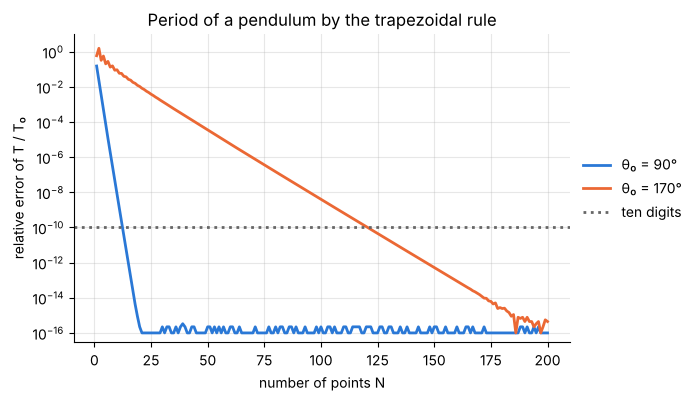

In [3]:
def period_ratio(k, N):
    """T / T0 by the N-point periodic trapezoidal rule."""
    return periodic_trapezoid(lambda phi: 1 / np.sqrt(1 - k**2 * np.sin(phi) ** 2), N, period=np.pi) / np.pi

N_range = np.arange(1, 201)
pendulum = {}
print("  θ0      k        T/T0 (exact)    smallest N    d = arcosh(1/k)   fitted rate / 2d")
for degrees in (90, 170):
    k = np.sin(np.radians(degrees) / 2)
    exact = 2 / np.pi * ellipk(k**2)
    error = np.array([abs(period_ratio(k, N) / exact - 1) for N in N_range])
    N_needed = int(N_range[np.argmax(error < 1e-10)])
    d = np.arccosh(1 / k)
    window = (error > 1e-12) & (error < 1e-2)                      # the straight part of the curve
    rate = -np.polyfit(N_range[window], np.log(error[window]), 1)[0]
    pendulum[degrees] = (k, exact, error, N_needed, d, rate)
    print(f"{degrees:4d}°  {k:.5f}  {exact:.12f} {N_needed:10d} {d:16.4f} {rate / (2 * d):16.3f}")

fig, ax = plt.subplots()
for degrees, (k, exact, error, N_needed, d, rate) in pendulum.items():
    ax.semilogy(N_range, np.maximum(error, 1e-16), label=f"θ₀ = {degrees}°")
ax.axhline(1e-10, color="0.4", ls=":", label="ten digits")
ax.set(xlabel="number of points N", ylabel="relative error of T / T₀", ylim=(3e-17, 10),
       title="Period of a pendulum by the trapezoidal rule")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

In [4]:
# verify: the complete elliptic integral from SciPy, the small-amplitude series, and the predicted rate exp(-2dN)
for degrees, (k, exact, error, N_needed, d, rate) in pendulum.items():
    assert abs(period_ratio(k, N_needed) / exact - 1) < 1e-10 <= error[N_needed - 2]     # N_needed works, N_needed - 1 does not
    assert (error[N_needed - 1:] < 1e-10).all()                                          # and so does every larger N
    assert abs(rate / (2 * d) - 1) < 0.1                                                 # geometric rate set by the singularity
small = np.sin(np.radians(10) / 2)
assert abs(period_ratio(small, 16) - (1 + small**2 / 4 + 9 * small**4 / 64 + 25 * small**6 / 256)) < 1e-9
assert (pendulum[90][3], pendulum[170][3]) == (13, 121)

**Answer.** $T/T_0 = 1.180340599016$ for $\theta_0 = 90°$ and $2.439362719674$ for
$\theta_0 = 170°$. Ten digits need $N = 13$ points in the first case and $N = 121$ in the
second. The integrand has branch points at a distance $d = \operatorname{arcosh}(1/k)$ from the
real axis and the error falls like $e^{-2dN}$. For $90°$, $d = 0.881$. For $170°$ the pendulum
is released close to the inverted position, $k = 0.996$ is close to 1, the singularities have
moved in to $d = 0.087$, and the integrand has a tall narrow peak at $\varphi = \pi/2$ that
needs nine times as many points to resolve. The convergence is still geometric.

## Exercise 2

The fraction of black-body radiation emitted between the wavelengths $\lambda_1$ and
$\lambda_2$ is $F = \dfrac{15}{\pi^4}\displaystyle\int_{x_2}^{x_1}\frac{x^3}{e^x - 1}\,dx$ with
$x_i = c_2/(\lambda_iT)$ and $c_2 = 14388$ μm K. For the sun, $T = 5800$ K, compute the
fraction emitted in the visible band from 0.4 μm to 0.7 μm with Clenshaw-Curtis and with
Gauss-Legendre, and find how many points each rule needs for an error below $10^{-10}$.

The limits are $x_2 = c_2/(0.7\,T) = 3.54$ and $x_1 = c_2/(0.4\,T) = 6.20$. Map each rule to
$[x_2, x_1]$ and compare rules with the same number of points. For a reference that owes
nothing to either rule, expand $1/(e^x - 1) = \sum_{n\ge1}e^{-nx}$ and integrate term by term:

$$\frac{15}{\pi^4}\int_x^\infty\frac{s^3}{e^s - 1}\,ds = \frac{15}{\pi^4}\sum_{n\ge1}e^{-nx}\Big(\frac{x^3}{n} + \frac{3x^2}{n^2} + \frac{6x}{n^3} + \frac{6}{n^4}\Big).$$

The integrand is analytic on the interval and its nearest singularities are at $x = \pm2\pi i$
(the point $x = 0$ is not one), so both rules should converge geometrically and fast.

x from 3.5438 to 6.2017
visible fraction: series 0.367654104491   Clenshaw-Curtis 0.367654104491   Gauss-Legendre 0.367654104491
points needed for an error below 1e-10: Clenshaw-Curtis 9, Gauss-Legendre 6


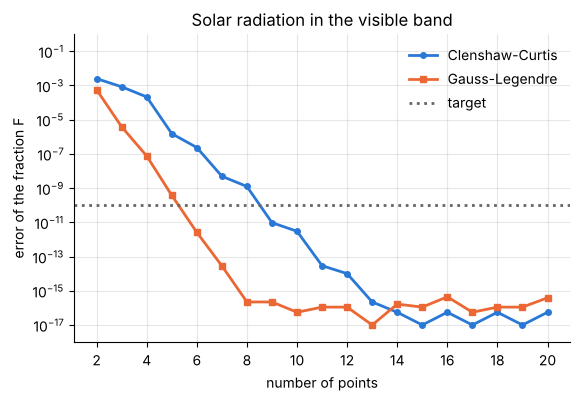

In [5]:
c2, T_sun = 14388.0, 5800.0                                        # μm K, K
x_lower, x_upper = c2 / (0.7 * T_sun), c2 / (0.4 * T_sun)
planck = lambda x: 15 / np.pi**4 * x**3 / np.expm1(x)

def fraction_above(x, terms=60):
    """Series for the integral of the Planck function from x to infinity."""
    n = np.arange(1, terms + 1)
    return 15 / np.pi**4 * np.sum(np.exp(-n * x) * (x**3 / n + 3 * x**2 / n**2 + 6 * x / n**3 + 6 / n**4))

F_series = fraction_above(x_lower) - fraction_above(x_upper)

def visible_fraction(rule, n):
    """Fraction in the visible band from n points of 'cc' or 'gauss'."""
    xi, w = clenshaw_curtis(n - 1) if rule == "cc" else gauss_legendre(n)
    x = x_lower + (x_upper - x_lower) * (xi + 1) / 2
    return (x_upper - x_lower) / 2 * w @ planck(x)

points = np.arange(2, 21)
band_error = {rule: np.array([abs(visible_fraction(rule, n) - F_series) for n in points]) for rule in ("cc", "gauss")}
n_cc, n_gauss = (int(points[np.argmax(band_error[rule] < 1e-10)]) for rule in ("cc", "gauss"))
print(f"x from {x_lower:.4f} to {x_upper:.4f}")
print(f"visible fraction: series {F_series:.12f}   Clenshaw-Curtis {visible_fraction('cc', 20):.12f}   Gauss-Legendre {visible_fraction('gauss', 20):.12f}")
print(f"points needed for an error below 1e-10: Clenshaw-Curtis {n_cc}, Gauss-Legendre {n_gauss}")

fig, ax = plt.subplots()
ax.semilogy(points, np.maximum(band_error["cc"], 1e-17), "o-", ms=4, label="Clenshaw-Curtis")
ax.semilogy(points, np.maximum(band_error["gauss"], 1e-17), "s-", ms=4, label="Gauss-Legendre")
ax.axhline(1e-10, color="0.4", ls=":", label="target")
ax.set(xlabel="number of points", ylabel="error of the fraction F", xticks=points[::2], ylim=(1e-18, 1),
       title="Solar radiation in the visible band")
ax.legend(frameon=False, loc="upper right");

In [6]:
# verify: the series (independent of both rules), the total over all wavelengths, and the count of points
assert abs(visible_fraction("cc", 20) - F_series) < 1e-14 and abs(visible_fraction("gauss", 20) - F_series) < 1e-14
assert abs(fraction_above(0.0, terms=20000) - 1) < 1e-12           # all wavelengths together: F = 1, since the sum of 1/n⁴ is π⁴/90
assert (band_error["cc"][points >= n_cc] < 1e-10).all() and (band_error["gauss"][points >= n_gauss] < 1e-10).all()
assert (n_cc, n_gauss) == (9, 6)

**Answer.** $F = 0.367654$: the sun emits 36.8 % of its radiation in the visible band.
Gauss-Legendre reaches an error below $10^{-10}$ with 6 points and Clenshaw-Curtis with 9. The
integrand is so smooth on this short interval that it is nearly a polynomial of low degree,
which is the situation in which Gauss shows its factor-of-two advantage (10.4). Either way a
dozen function values replace a table look-up.

## Exercise 3

The laminar velocity profile of a power-law fluid in a tube is
$u/u_{\max} = 1 - r^{(n+1)/n}$, with mean-to-maximum ratio $(n+1)/(3n+1)$. For $n = 0.4$
compute $2\int_0^1u\,r\,dr$ with Clenshaw-Curtis for $N = 8, 12, 16, 20, 24$ and measure the
order of convergence. Compare it with the prediction of 10.7. Then find a substitution that
makes the integrand a polynomial and confirm that the rule becomes exact.

For $n = 0.4$ the exponent is $(n+1)/n = 3.5$, so the integrand is $r - r^{4.5}$. The term
$r^{4.5}$ is singular at the end point $r = 0$ (its fifth derivative is infinite there), and
the rule of 10.7 for a singularity of power $\alpha = 4.5$ predicts the order
$2\alpha + 2 = 11$. The substitution $r = t^2$ turns $r^{4.5}$ into $t^9$:

$$2\int_0^1\big(1 - r^{3.5}\big)\,r\,dr = 2\int_0^1\big(1 - t^7\big)\,t^2\,2t\,dt ,$$

a polynomial of degree 10 in $t$, which Clenshaw-Curtis integrates exactly for $N \ge 10$.

   N    error, integrating in r    error, integrating in t (r = t²)
   8              4.2e-09                      1.4e-07
  12              4.4e-11                      1.1e-16
  16              1.8e-12                      1.1e-16
  20              1.5e-13                      2.2e-16
  24              2.0e-14                      1.1e-16
observed order in r: 11.13    predicted 2 x 4.5 + 2 = 11
in t with N = 10: 0.636363636363636    7/11 = 0.636363636363636


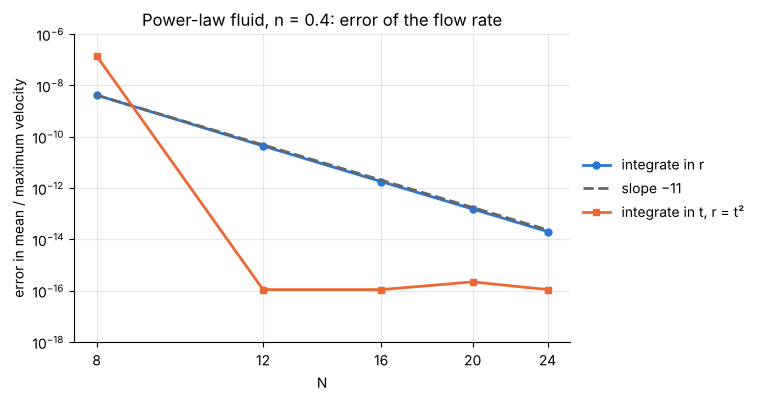

In [7]:
n_power = 0.4
exponent = (n_power + 1) / n_power
ratio_exact = (n_power + 1) / (3 * n_power + 1)                     # 7/11

N_list = np.array([8, 12, 16, 20, 24])
error_r, error_t = [], []
for N in N_list:
    r, w = cc_on(N, 0.0, 1.0)
    error_r.append(abs(2 * w @ ((1 - r**exponent) * r) - ratio_exact))
    t = r                                                          # the same nodes, read as values of t
    error_t.append(abs(2 * w @ ((1 - t**7) * t**2 * 2 * t) - ratio_exact))
error_r, error_t = np.array(error_r), np.array(error_t)
order = -np.polyfit(np.log(N_list), np.log(error_r), 1)[0]

print("   N    error, integrating in r    error, integrating in t (r = t²)")
for N, e_r, e_t in zip(N_list, error_r, error_t):
    print(f"{N:4d} {e_r:20.1e} {e_t:28.1e}")
print(f"observed order in r: {order:.2f}    predicted 2 x 4.5 + 2 = 11")
t, w = cc_on(10, 0.0, 1.0)
ratio_10 = 2 * w @ ((1 - t**7) * t**2 * 2 * t)
print(f"in t with N = 10: {ratio_10:.15f}    7/11 = {7 / 11:.15f}")

fig, ax = plt.subplots()
ax.loglog(N_list, error_r, "o-", ms=5, label="integrate in r")
ax.loglog(N_list, error_r[0] * (N_list / N_list[0]) ** -11.0, "--", color="0.4", label="slope −11")
ax.loglog(N_list, np.maximum(error_t, 1e-17), "s-", ms=5, label="integrate in t, r = t²")
ax.set(xlabel="N", ylabel="error in mean / maximum velocity", ylim=(1e-18, 1e-6), xticks=N_list, xticklabels=N_list,
       title="Power-law fluid, n = 0.4: error of the flow rate")
ax.minorticks_off()
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

In [8]:
# verify: the exact ratio (n+1)/(3n+1) = 7/11, the order predicted in 10.7, and exactness after the substitution
assert abs(order - 11) < 0.5
assert abs(ratio_10 - 7 / 11) < 1e-14 and error_t[N_list >= 10].max() < 1e-14     # exact (to rounding) as soon as N ≥ 10
assert error_t[N_list == 8][0] > 1e-8                                              # and not before: degree 10 needs N = 10

**Answer.** Integrated in $r$, the error falls from $4.2\times10^{-9}$ at $N = 8$ to
$2.0\times10^{-14}$ at $N = 24$, an observed order of 11.1 against the predicted
$2\times4.5 + 2 = 11$ (larger $N$ would run into rounding error). With $r = t^2$ the integrand
is a polynomial of degree 10 and the rule returns $7/11 = 0.636364$ to rounding error for every
$N \ge 10$; $N = 8$ is not enough. The singularity here is mild, so the rule converges quickly even without the
substitution, but the substitution turns "quickly" into "exactly" at no cost.

## Exercise 4

The Einstein model of a solid gives the heat capacity
$c_v/(3R) = y^2e^{y}/(e^{y} - 1)^2$ with $y = \Theta/T$. For $\Theta = 400$ K use
`running_integral`, mapped to the interval from 100 K to 1000 K with $N = 32$, to compute
the energy $\int_{100}^{T}c_v\,dT'/(3R)$ at every grid temperature. Compare with the exact
result $\Theta/(e^{\Theta/T} - 1) - \Theta/(e^{\Theta/100} - 1)$ and report the largest error.

`running_integral` works on $[-1, 1]$. With $T = a + (b - a)(x + 1)/2$, $a = 100$ K and
$b = 1000$ K, the integral over $T$ is the integral over $x$ times $(b - a)/2 = 450$ K. The
lower limit $x = -1$ is $T = 100$ K, and it is the **last** grid point (index $N$).

energy at 1000 K: 805.834968562 K   exact 805.834968542 K
largest error over the grid: 3.8e-08 K   (relative to the largest value: 4.8e-11)


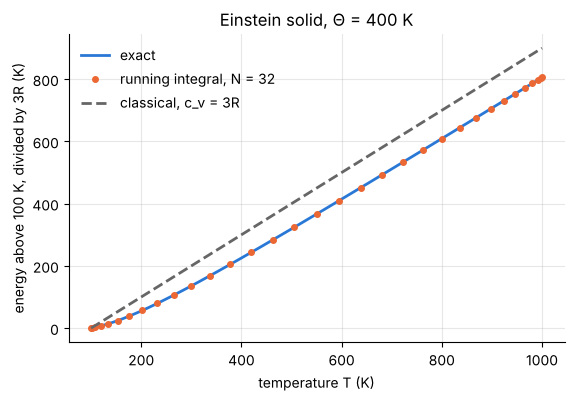

In [9]:
Theta, T_low, T_high, N = 400.0, 100.0, 1000.0, 32

def einstein_cv(T):
    """Heat capacity c_v / (3R) of the Einstein solid."""
    y = Theta / T
    return y**2 * np.exp(y) / np.expm1(y) ** 2

x = cheb(N)[1]
T_grid = T_low + (T_high - T_low) * (x + 1) / 2
energy = (T_high - T_low) / 2 * running_integral(einstein_cv(T_grid))          # in K, the energy divided by 3R
energy_exact = Theta / np.expm1(Theta / T_grid) - Theta / np.expm1(Theta / T_low)
energy_error = np.abs(energy - energy_exact).max()
print(f"energy at 1000 K: {energy[0]:.9f} K   exact {energy_exact[0]:.9f} K")
print(f"largest error over the grid: {energy_error:.1e} K   (relative to the largest value: {energy_error / energy_exact[0]:.1e})")

fig, ax = plt.subplots()
T_fine = np.linspace(T_low, T_high, 300)
ax.plot(T_fine, Theta / np.expm1(Theta / T_fine) - Theta / np.expm1(Theta / T_low), label="exact")
ax.plot(T_grid, energy, "o", ms=4, label="running integral, N = 32")
ax.plot(T_fine, T_fine - T_low, "--", color="0.4", label="classical, c_v = 3R")
ax.set(xlabel="temperature T (K)", ylabel="energy above 100 K, divided by 3R (K)", title="Einstein solid, Θ = 400 K")
ax.legend(frameon=False, loc="upper left");

In [10]:
# verify: the closed form at every grid point, a Clenshaw-Curtis value of the whole integral, and the high-temperature limit
T_cc, w_cc = cc_on(N, T_low, T_high)
total_cc = w_cc @ einstein_cv(T_cc)
print(f"whole integral, 100 K to 1000 K: running integral {energy[0]:.9f}   Clenshaw-Curtis {total_cc:.9f}   exact {energy_exact[0]:.9f}")
print(f"Clenshaw-Curtis error: {abs(total_cc - energy_exact[0]):.1e} K")
assert energy_error < 1e-7 and energy[N] == 0.0                     # index N is T = 100 K, the lower limit
assert abs(total_cc - energy_exact[0]) < 1e-10 and abs(energy[0] - total_cc) < 1e-7
y = 0.1
assert abs(einstein_cv(Theta / y) - (1 - y**2 / 12 + y**4 / 240)) < 1e-8      # c_v → 3R from below when T >> Θ

whole integral, 100 K to 1000 K: running integral 805.834968562   Clenshaw-Curtis 805.834968542   exact 805.834968542
Clenshaw-Curtis error: 2.0e-12 K


**Answer.** The energy between 100 K and 1000 K is $805.835$ K times $3R$, and the largest
error over the 33 grid temperatures is $3.8\times10^{-8}$ K, a relative error of
$5\times10^{-11}$. One linear solve gives the whole energy curve $U(T)$, which is what a heat
balance needs. Note that the Clenshaw-Curtis rule on the same 33 values gives the total with
an error of only $2\times10^{-12}$ K: when only the final value is wanted, the weights are the
better tool.

## Exercise 5

The radiation view factor between two directly opposed parallel unit squares a distance
$h = 1$ apart is the four-dimensional integral
$F_{12} = \displaystyle\int_0^1\!\!\int_0^1\!\!\int_0^1\!\!\int_0^1\frac{h^2}{\pi\,\big[(x_1-x_2)^2 + (y_1-y_2)^2 + h^2\big]^2}\,dx_1\,dy_1\,dx_2\,dy_2 .$
Evaluate it with a tensor product of four Clenshaw-Curtis rules with $N = 16$ in each
direction. The tabulated value is 0.1998.

With $N = 16$ there are $17^4 = 83521$ points, which is no burden. Build the integrand as a
four-dimensional array by broadcasting and contract each axis with the weight vector. For
a check, the classical closed form for two directly opposed $a \times b$ rectangles a distance
$h$ apart, with $X = a/h$ and $Y = b/h$, is

$$F_{12} = \frac{2}{\pi XY}\Big[\tfrac12\ln\frac{(1+X^2)(1+Y^2)}{1+X^2+Y^2} + X\sqrt{1+Y^2}\arctan\frac{X}{\sqrt{1+Y^2}} + Y\sqrt{1+X^2}\arctan\frac{Y}{\sqrt{1+X^2}} - X\arctan X - Y\arctan Y\Big].$$

In [11]:
def view_factor(N, h=1.0):
    """View factor between opposed unit squares a distance h apart: four Clenshaw-Curtis rules with N + 1 points each."""
    s, w = cc_on(N, 0.0, 1.0)
    x1, y1, x2, y2 = s[:, None, None, None], s[None, :, None, None], s[None, None, :, None], s[None, None, None, :]
    kernel = h**2 / (np.pi * ((x1 - x2) ** 2 + (y1 - y2) ** 2 + h**2) ** 2)
    return np.einsum("ijkl,i,j,k,l->", kernel, w, w, w, w)

def view_factor_exact(X, Y):
    """Closed form for opposed rectangles with sides X and Y in units of the separation."""
    return 2 / (np.pi * X * Y) * (0.5 * np.log((1 + X**2) * (1 + Y**2) / (1 + X**2 + Y**2))
                                  + X * np.sqrt(1 + Y**2) * np.arctan(X / np.sqrt(1 + Y**2))
                                  + Y * np.sqrt(1 + X**2) * np.arctan(Y / np.sqrt(1 + X**2))
                                  - X * np.arctan(X) - Y * np.arctan(Y))

F12 = view_factor(16)
print(f"F12 with N = 16: {F12:.12f}    closed form: {view_factor_exact(1.0, 1.0):.12f}    tabulated: 0.1998")
print("   N    points     error against the closed form")
for N in (2, 4, 8, 12, 16):
    print(f"{N:4d} {(N + 1) ** 4:9d} {abs(view_factor(N) - view_factor_exact(1.0, 1.0)):16.1e}")

F12 with N = 16: 0.199824895698    closed form: 0.199824895698    tabulated: 0.1998
   N    points     error against the closed form
   2        81          5.9e-03
   4       625          2.2e-05
   8      6561          5.2e-09
  12     28561          4.1e-13
  16     83521          2.4e-15


In [12]:
# verify: the tabulated value, the closed form, and a second separation
assert round(F12, 4) == 0.1998
assert abs(F12 - view_factor_exact(1.0, 1.0)) < 1e-12
assert abs(view_factor(16, h=2.0) - view_factor_exact(0.5, 0.5)) < 1e-12
assert view_factor(16, h=2.0) < F12 < 1                              # further apart, less of the radiation arrives

**Answer.** $F_{12} = 0.199825$, which rounds to the tabulated 0.1998 and agrees with the
closed form to $2\times10^{-15}$. A fifth of the radiation leaving one square reaches the
other. The error falls geometrically with $N$, and $N = 8$ (6561 points) already gives seven
digits, so a four-dimensional integral with a smooth integrand is well within reach of a
tensor-product rule. View factors between surfaces that touch are harder, because the kernel
is then singular at the common edge.